<a href="https://colab.research.google.com/github/zahraasalahanany/covid19-reinfection-analysis/blob/main/COVID_19_Reinfection_and_Health_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("D:\\FAM\\Zahraa\\Ai\\archive2\\covid_related_disease_data.csv")
df

,Patient_ID,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,...,Reinfection,Date_of_Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,1,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,...,No,NaN,Yes,None,1,2022-09-22,None,Healthcare,Never,27.7
1,2,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,...,No,NaN,No,None,0,NaN,None,Healthcare,Never,21.9
2,3,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,...,No,NaN,Yes,Janssen,3,2024-05-14,None,Unemployed,Never,22.7
3,4,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,...,Yes,2024-08-24,Yes,AstraZeneca,1,2024-10-31,None,Office Worker,Never,27.7
4,5,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,...,No,NaN,Yes,None,2,2023-07-05,None,Student,Never,11.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2996,43,Male,Nordjylland,Hypertension,2022-10-19,XBB.1.5,Severe,Critical,No,...,No,NaN,Yes,None,1,2024-09-20,None,Driver,Never,22.0
2996,2997,36,Female,Syddanmark,Obesity,2022-12-16,Omicron,Moderate,Low,No,...,No,NaN,Yes,Pfizer,2,2023-10-05,None,Healthcare,Never,27.8
2997,2998,75,Female,Sjælland,Cardiovascular,2023-09-30,Beta,Severe,Moderate,No,...,No,NaN,Yes,Moderna,3,2023-05-13,None,Teacher,Former,20.9
2998,2999,45,Female,Hovedstaden,Asthma,2023-06-06,Delta,Severe,Moderate,No,...,No,NaN,Yes,AstraZeneca,1,2024-05-13,None,Student,Never,19.3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               3000 non-null   int64  
 1   Age                      3000 non-null   int64  
 2   Gender                   3000 non-null   object 
 3   Region                   3000 non-null   object 
 4   Preexisting_Condition    3000 non-null   object 
 5   Date_of_Infection        3000 non-null   object 
 6   COVID_Strain             3000 non-null   object 
 7   Symptoms                 3000 non-null   object 
 8   Severity                 3000 non-null   object 
 9   Hospitalized             3000 non-null   object 
 10  Hospital_Admission_Date  876 non-null    object 
 11  Hospital_Discharge_Date  876 non-null    object 
 12  ICU_Admission            3000 non-null   object 
 13  Ventilator_Support       3000 non-null   object 
 14  Recovered               

In [ ]:
df.shape

(3000, 26)

In [ ]:
df.describe()

,Patient_ID,Age,Doses_Received,BMI
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,53.944000,0.981667,25.096500
std,866.169729,20.872919,1.154025,4.898435
min,1.000000,18.000000,0.000000,10.200000
25%,750.750000,36.000000,0.000000,21.800000
50%,1500.500000,54.000000,0.000000,25.100000
75%,2250.250000,72.000000,2.000000,28.500000
max,3000.000000,89.000000,3.000000,44.600000


In [ ]:
df.isnull().sum()

Patient_ID                    0
Age                           0
Gender                        0
Region                        0
Preexisting_Condition         0
Date_of_Infection             0
COVID_Strain                  0
Symptoms                      0
Severity                      0
Hospitalized                  0
Hospital_Admission_Date    2124
Hospital_Discharge_Date    2124
ICU_Admission                 0
Ventilator_Support            0
Recovered                     0
Date_of_Recovery           1492
Reinfection                   0
Date_of_Reinfection        2715
Vaccination_Status            0
Vaccine_Type                  0
Doses_Received                0
Date_of_Last_Dose          1528
Long_COVID_Symptoms           0
Occupation                    0
Smoking_Status                0
BMI                           0
dtype: int64

In [ ]:
(df.isnull().sum()/len(df))*100

Patient_ID                  0.000000
Age                         0.000000
Gender                      0.000000
Region                      0.000000
Preexisting_Condition       0.000000
Date_of_Infection           0.000000
COVID_Strain                0.000000
Symptoms                    0.000000
Severity                    0.000000
Hospitalized                0.000000
Hospital_Admission_Date    70.800000
Hospital_Discharge_Date    70.800000
ICU_Admission               0.000000
Ventilator_Support          0.000000
Recovered                   0.000000
Date_of_Recovery           49.733333
Reinfection                 0.000000
Date_of_Reinfection        90.500000
Vaccination_Status          0.000000
Vaccine_Type                0.000000
Doses_Received              0.000000
Date_of_Last_Dose          50.933333
Long_COVID_Symptoms         0.000000
Occupation                  0.000000
Smoking_Status              0.000000
BMI                         0.000000
dtype: float64

In [ ]:
df=df.drop(['Patient_ID','Hospital_Admission_Date','Hospital_Discharge_Date','Date_of_Reinfection'],axis=1)

In [ ]:
numerical_col=df.select_dtypes(include=['number']).columns
numerical_col

Index(['Age', 'Doses_Received', 'BMI'], dtype='object')

In [ ]:
categorical_col=df.select_dtypes(include=['object']).columns
categorical_col

Index(['Gender', 'Region', 'Preexisting_Condition', 'Date_of_Infection',
       'COVID_Strain', 'Symptoms', 'Severity', 'Hospitalized', 'ICU_Admission',
       'Ventilator_Support', 'Recovered', 'Date_of_Recovery', 'Reinfection',
       'Vaccination_Status', 'Vaccine_Type', 'Date_of_Last_Dose',
       'Long_COVID_Symptoms', 'Occupation', 'Smoking_Status'],
      dtype='object')

In [ ]:
for col in categorical_col:
    df[col]=df[col].fillna(df[col].mode()[0])

In [ ]:
df.duplicated().sum()

0

In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,...,Date_of_Recovery,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,No,...,2023-04-19,No,Yes,None,1,2022-09-22,None,Healthcare,Never,27.7
1,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,No,...,2024-08-25,No,No,None,0,2022-12-18,None,Healthcare,Never,21.9
2,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,Yes,...,2024-08-25,No,Yes,Janssen,3,2024-05-14,None,Unemployed,Never,22.7
3,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,No,...,2025-02-09,Yes,Yes,AstraZeneca,1,2024-10-31,None,Office Worker,Never,27.7
4,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,No,...,2024-08-25,No,Yes,None,2,2023-07-05,None,Student,Never,11.9


In [ ]:
df2=df.drop(['Date_of_Infection', 'Date_of_Recovery', 'Date_of_Last_Dose',
                   'Symptoms', 'Long_COVID_Symptoms'], axis=1)

df2.duplicated().sum()

0

In [ ]:
df3=df.drop(['Date_of_Infection', 'Date_of_Recovery', 'Date_of_Last_Dose', ], axis=1)

df3.duplicated().sum()

0

In [ ]:
df4=df.drop(['Symptoms', 'Long_COVID_Symptoms' ], axis=1)

df4.duplicated().sum()

0

In [ ]:
for col in df.columns:
    print(f"\ncolumn:{col}")
    print(df[col].value_counts(normalize=True).head())


column:Age
85    0.018333
30    0.017333
75    0.017333
71    0.017000
79    0.017000
Name: Age, dtype: float64

column:Gender
Female    0.509
Male      0.491
Name: Gender, dtype: float64

column:Region
Midtjylland    0.209333
Hovedstaden    0.204000
Sjælland       0.203000
Syddanmark     0.199000
Nordjylland    0.184667
Name: Region, dtype: float64

column:Preexisting_Condition
Cardiovascular    0.177667
Obesity           0.170333
Diabetes          0.170333
Hypertension      0.164333
Asthma            0.161000
Name: Preexisting_Condition, dtype: float64

column:Date_of_Infection
2023-05-02    0.003667
2023-12-17    0.003667
2024-01-14    0.003667
2022-07-10    0.003667
2023-07-26    0.003333
Name: Date_of_Infection, dtype: float64

column:COVID_Strain
Beta       0.207333
Omicron    0.205333
Delta      0.200000
XBB.1.5    0.194333
Alpha      0.193000
Name: COVID_Strain, dtype: float64

column:Symptoms
Severe      0.337333
Mild        0.336667
Moderate    0.326000
Name: Symptoms, dtype

In [ ]:
df.duplicated().sum()

0

In [ ]:
df.shape

(3000, 22)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    3000 non-null   int64  
 1   Gender                 3000 non-null   object 
 2   Region                 3000 non-null   object 
 3   Preexisting_Condition  3000 non-null   object 
 4   Date_of_Infection      3000 non-null   object 
 5   COVID_Strain           3000 non-null   object 
 6   Symptoms               3000 non-null   object 
 7   Severity               3000 non-null   object 
 8   Hospitalized           3000 non-null   object 
 9   ICU_Admission          3000 non-null   object 
 10  Ventilator_Support     3000 non-null   object 
 11  Recovered              3000 non-null   object 
 12  Date_of_Recovery       3000 non-null   object 
 13  Reinfection            3000 non-null   object 
 14  Vaccination_Status     3000 non-null   object 
 15  Vacc

<function matplotlib.pyplot.show(close=None, block=None)>

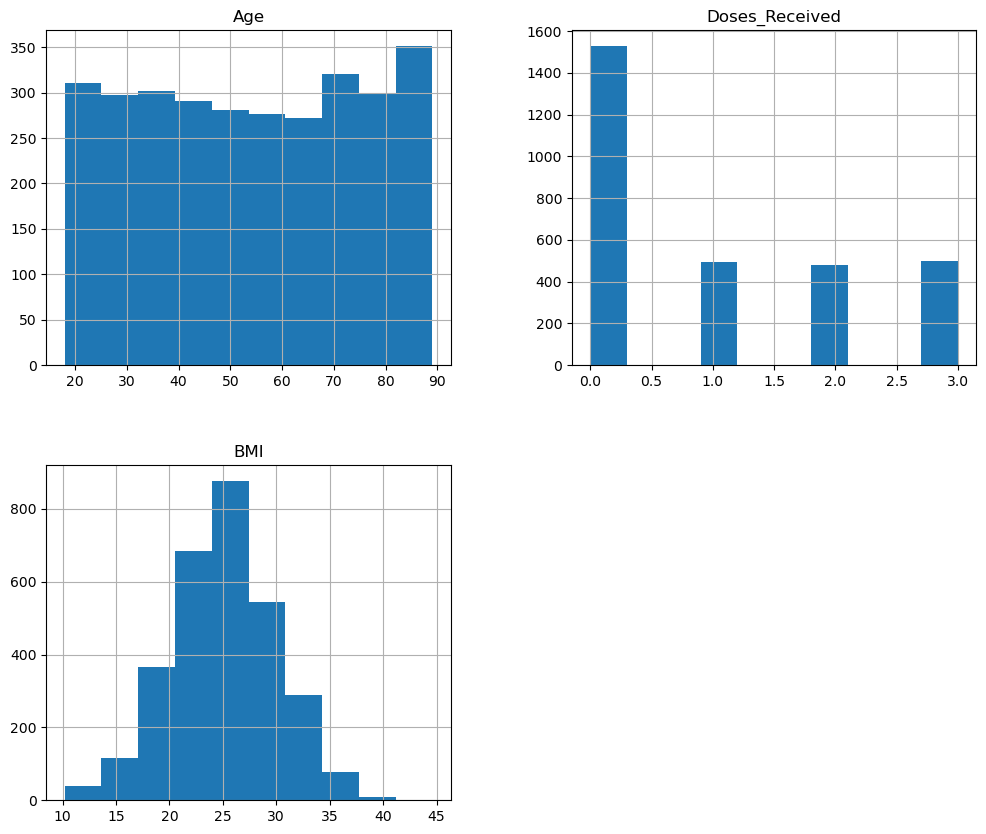

In [ ]:
df[numerical_col].hist(figsize=(12,10))
plt.show

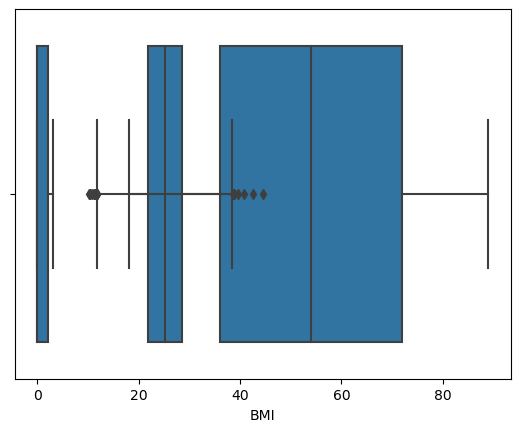

In [ ]:
for col in numerical_col:
    sns.boxplot(x=df[col])
    plt.show

In [ ]:
it Q1=df['BMI'].quantile(0.25)
Q3=df['BMI'].quantile(0.75)

IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
df=df[(df['BMI']>= lower_bound) & (df['BMI']<= upper_bound)]

In [ ]:
lower=df['BMI'].quantile(0.05)
upper=df['BMI'].quantile(0.95)
df['BMI']=df['BMI'].clip(lower,upper)

In [ ]:
df['BMI']=np.log(df['BMI'])

In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,...,Date_of_Recovery,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,No,...,2023-04-19,No,Yes,None,1,2022-09-22,None,Healthcare,Never,3.321432
1,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,No,...,2024-08-25,No,No,None,0,2022-12-18,None,Healthcare,Never,3.086487
2,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,Yes,...,2024-08-25,No,Yes,Janssen,3,2024-05-14,None,Unemployed,Never,3.122365
3,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,No,...,2025-02-09,Yes,Yes,AstraZeneca,1,2024-10-31,None,Office Worker,Never,3.321432
4,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,No,...,2024-08-25,No,Yes,None,2,2023-07-05,None,Student,Never,2.844909


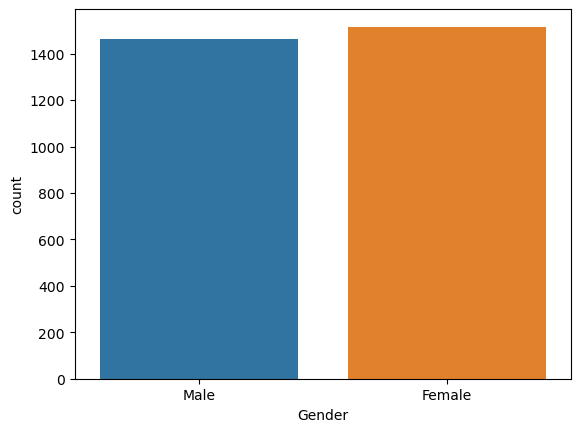

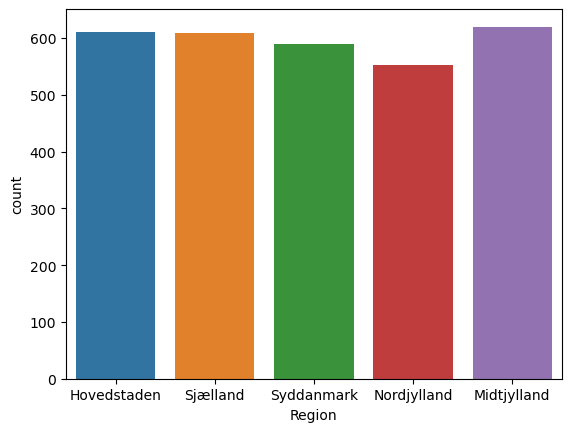

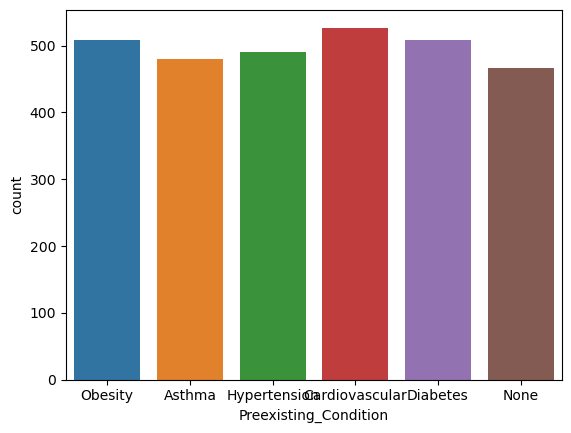

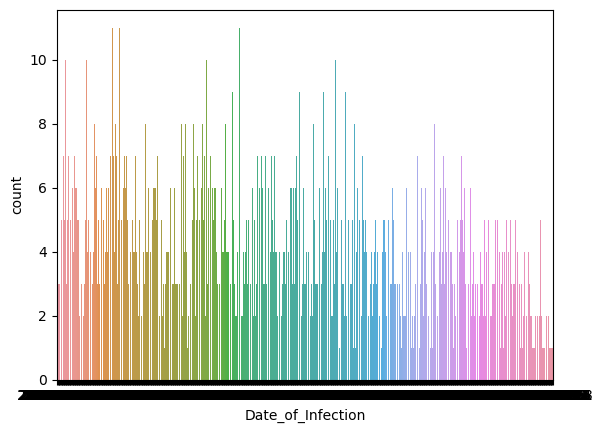

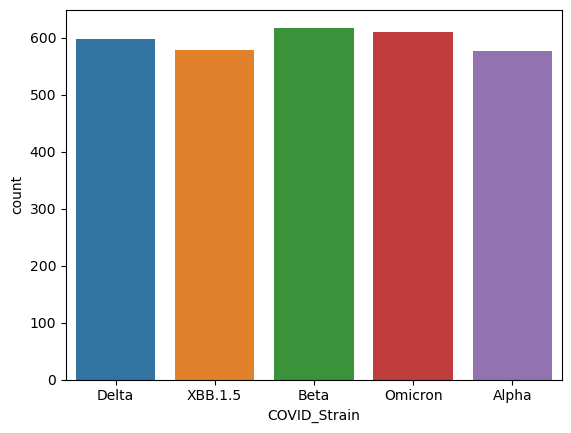

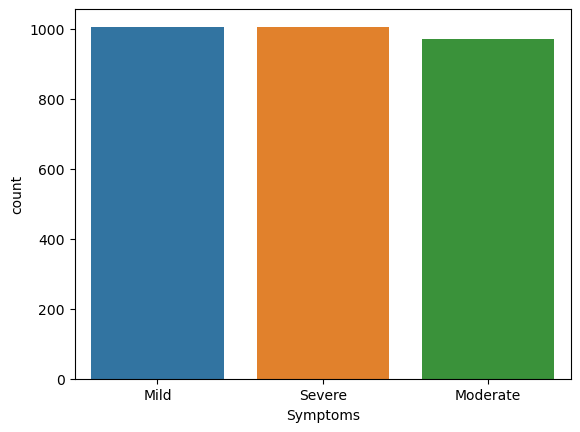

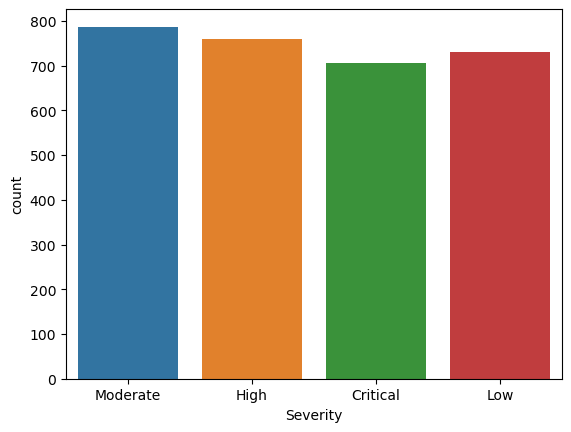

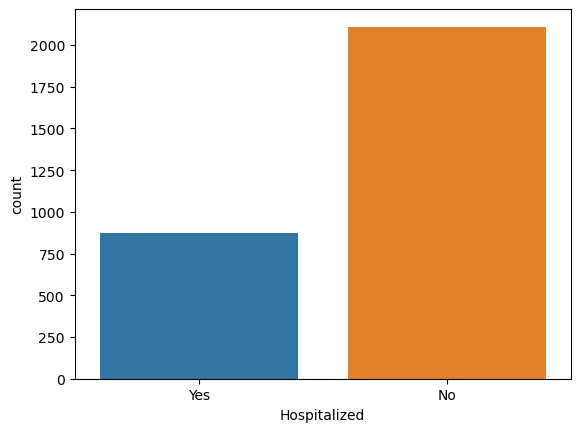

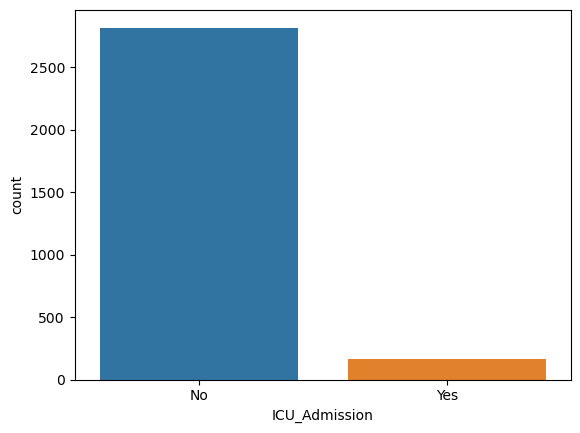

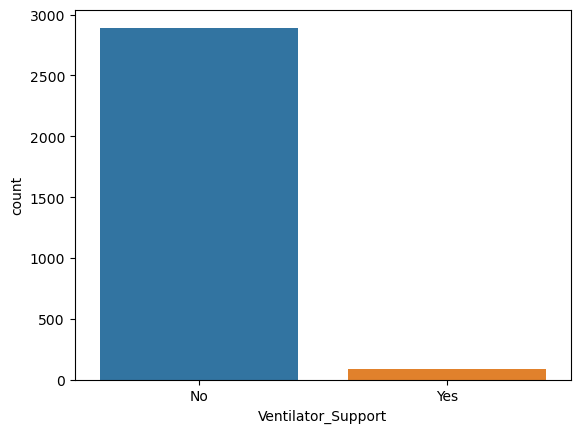

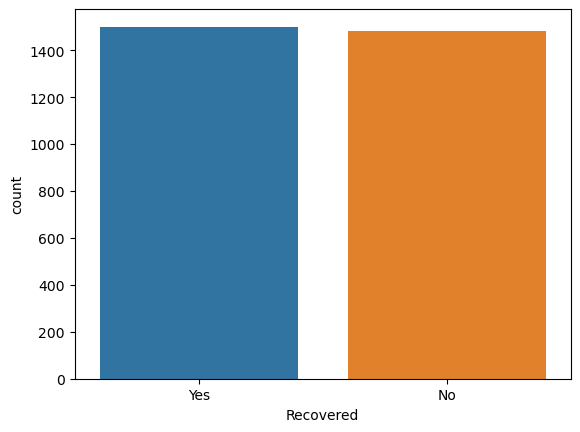

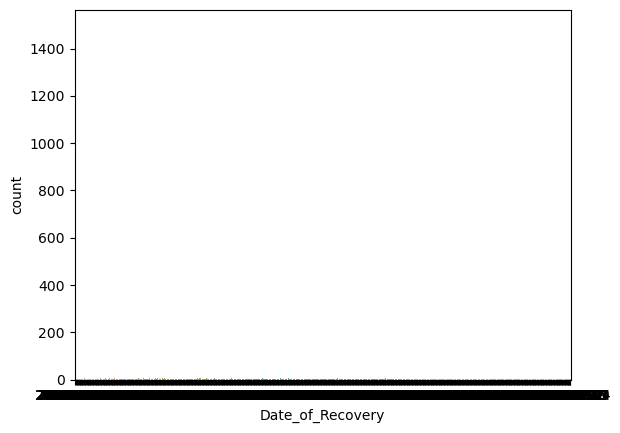

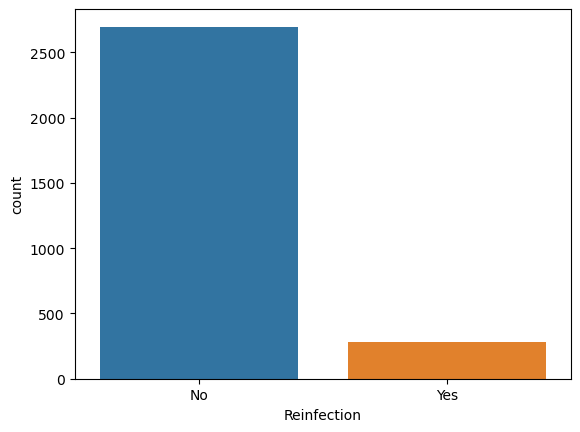

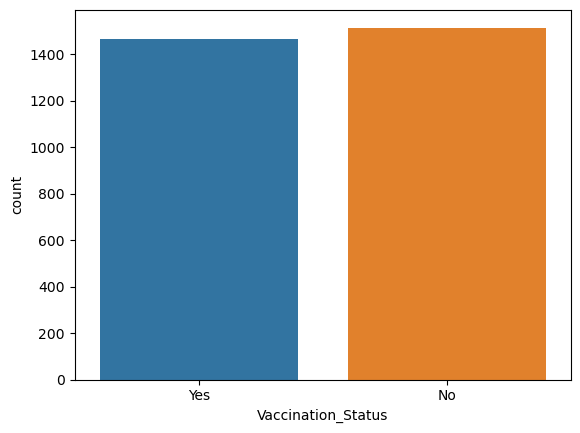

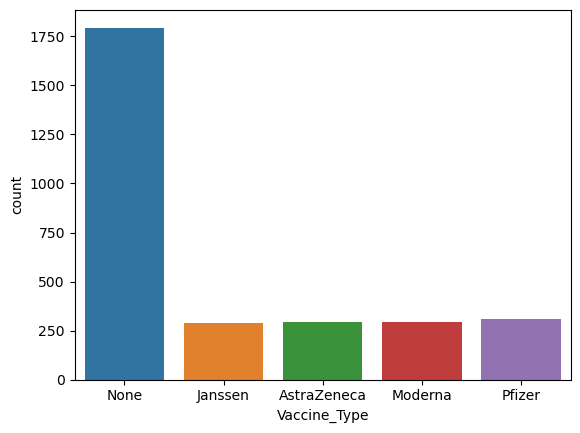

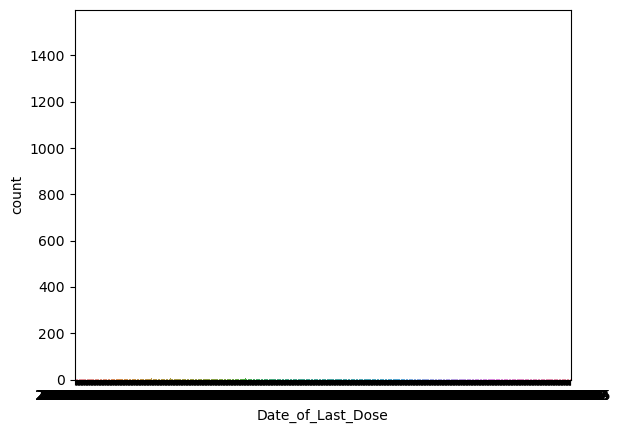

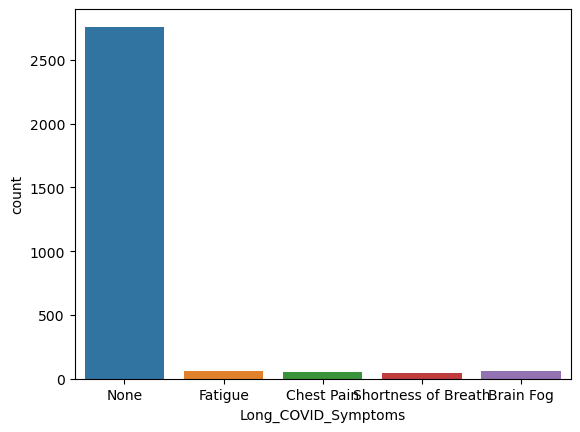

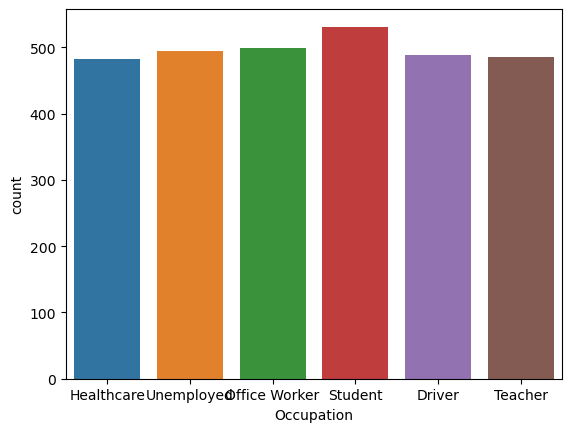

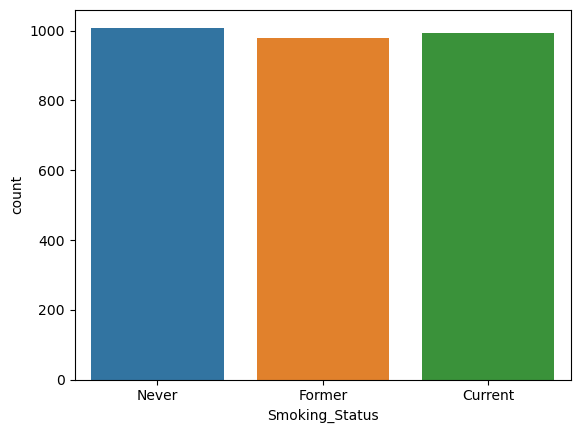

In [ ]:
for col in categorical_col:
    sns.countplot(data=df , x=col)
    plt.show()

In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,...,Date_of_Recovery,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,No,...,2023-04-19,No,Yes,None,1,2022-09-22,None,Healthcare,Never,3.321432
1,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,No,...,2024-08-25,No,No,None,0,2022-12-18,None,Healthcare,Never,3.086487
2,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,Yes,...,2024-08-25,No,Yes,Janssen,3,2024-05-14,None,Unemployed,Never,3.122365
3,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,No,...,2025-02-09,Yes,Yes,AstraZeneca,1,2024-10-31,None,Office Worker,Never,3.321432
4,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,No,...,2024-08-25,No,Yes,None,2,2023-07-05,None,Student,Never,2.844909


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in ['Gender', 'Region', 'Preexisting_Condition', 'COVID_Strain', 'Severity', 'Vaccine_Type', 'Occupation', 'Symptoms']:
    df[col] = le.fit_transform(df[col])


In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,...,Date_of_Recovery,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,69,1,0,5,2022-06-21,2,0,3,Yes,No,...,2023-04-19,No,Yes,3,1,2022-09-22,None,1,Never,3.321432
1,38,1,3,0,2024-02-02,4,0,3,No,No,...,2024-08-25,No,No,3,0,2022-12-18,None,1,Never,3.086487
2,41,0,4,3,2023-05-28,1,0,1,Yes,Yes,...,2024-08-25,No,Yes,1,3,2024-05-14,None,5,Never,3.122365
3,81,0,0,0,2023-08-13,2,2,1,No,No,...,2025-02-09,Yes,Yes,0,1,2024-10-31,None,2,Never,3.321432
4,50,0,4,1,2023-03-10,2,0,1,No,No,...,2024-08-25,No,Yes,3,2,2023-07-05,None,3,Never,2.844909


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2981 entries, 0 to 2999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    2981 non-null   int64  
 1   Gender                 2981 non-null   int32  
 2   Region                 2981 non-null   int32  
 3   Preexisting_Condition  2981 non-null   int32  
 4   Date_of_Infection      2981 non-null   object 
 5   COVID_Strain           2981 non-null   int32  
 6   Symptoms               2981 non-null   int32  
 7   Severity               2981 non-null   int32  
 8   Hospitalized           2981 non-null   object 
 9   ICU_Admission          2981 non-null   object 
 10  Ventilator_Support     2981 non-null   object 
 11  Recovered              2981 non-null   object 
 12  Date_of_Recovery       2981 non-null   object 
 13  Reinfection            2981 non-null   object 
 14  Vaccination_Status     2981 non-null   object 
 15  Vacc

In [ ]:
df.shape

(2981, 22)

In [ ]:
for col in ['Hospitalized','ICU_Admission','Ventilator_Support','Recovered','Reinfection','Vaccination_Status']:
    df[col] = df[col].str.strip().str.lower()
    df[col] = df[col].map({'yes': 1, 'no': 0})

In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,...,Date_of_Recovery,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,69,1,0,5,2022-06-21,2,0,3,1,0,...,2023-04-19,0,1,3,1,2022-09-22,None,1,Never,3.321432
1,38,1,3,0,2024-02-02,4,0,3,0,0,...,2024-08-25,0,0,3,0,2022-12-18,None,1,Never,3.086487
2,41,0,4,3,2023-05-28,1,0,1,1,1,...,2024-08-25,0,1,1,3,2024-05-14,None,5,Never,3.122365
3,81,0,0,0,2023-08-13,2,2,1,0,0,...,2025-02-09,1,1,0,1,2024-10-31,None,2,Never,3.321432
4,50,0,4,1,2023-03-10,2,0,1,0,0,...,2024-08-25,0,1,3,2,2023-07-05,None,3,Never,2.844909


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2981 entries, 0 to 2999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    2981 non-null   int64  
 1   Gender                 2981 non-null   int32  
 2   Region                 2981 non-null   int32  
 3   Preexisting_Condition  2981 non-null   int32  
 4   Date_of_Infection      2981 non-null   object 
 5   COVID_Strain           2981 non-null   int32  
 6   Symptoms               2981 non-null   int32  
 7   Severity               2981 non-null   int32  
 8   Hospitalized           2981 non-null   int64  
 9   ICU_Admission          2981 non-null   int64  
 10  Ventilator_Support     2981 non-null   int64  
 11  Recovered              2981 non-null   int64  
 12  Date_of_Recovery       2981 non-null   object 
 13  Reinfection            2981 non-null   int64  
 14  Vaccination_Status     2981 non-null   int64  
 15  Vacc

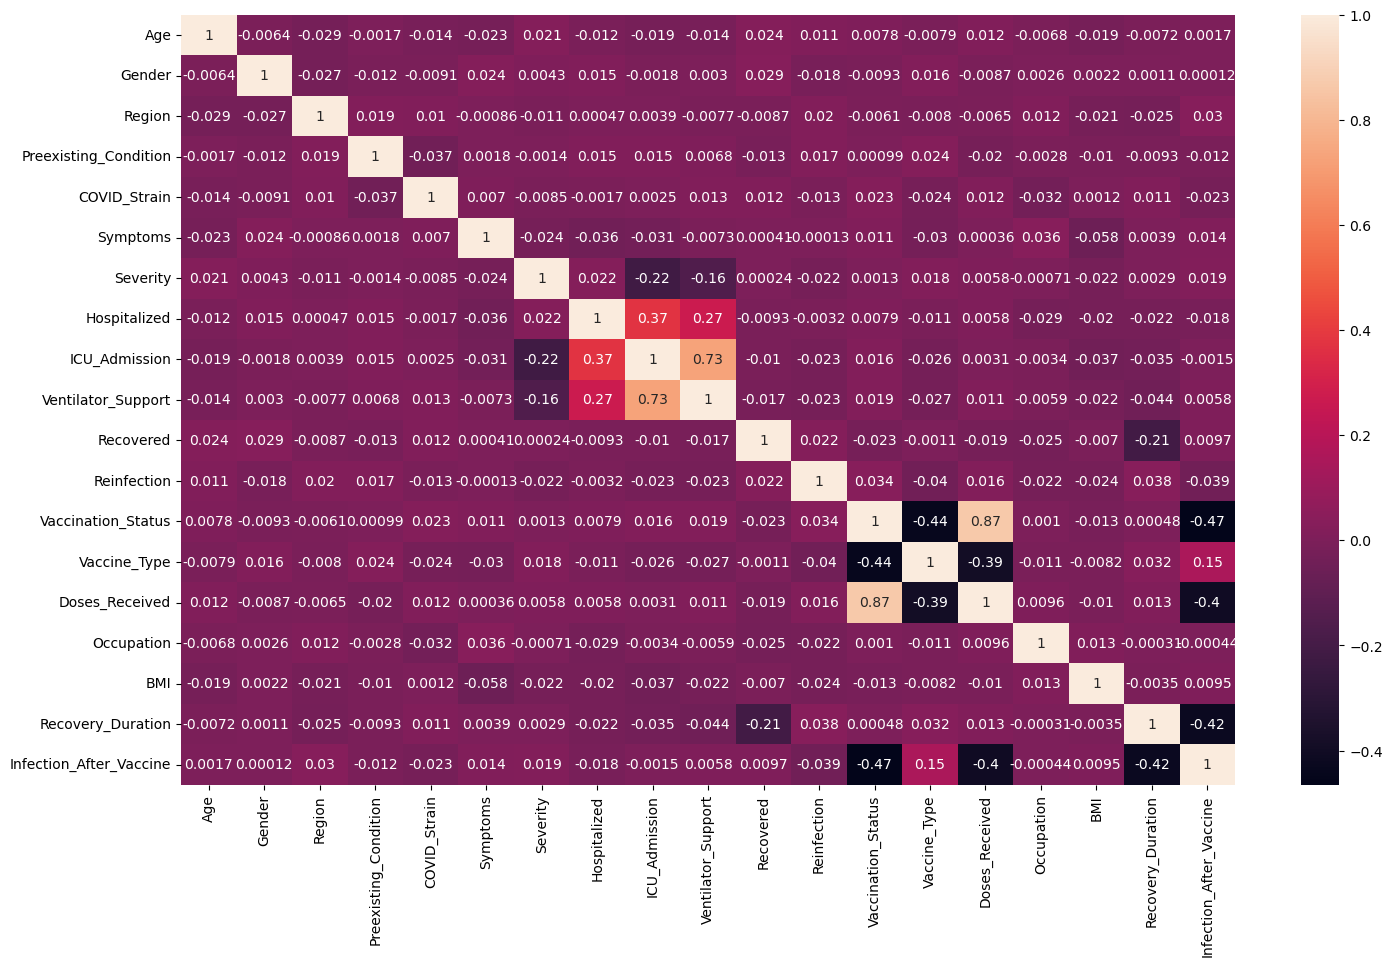

In [ ]:
plt.figure(figsize=(17, 10))
sns.heatmap(df.corr(), annot=True)
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df[numerical_col]=scaler.fit_transform(df[numerical_col])

In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,...,Date_of_Recovery,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,0.722490,1,0,5,2022-06-21,2,0,3,1,0,...,2023-04-19,0,1,3,0.013074,2022-09-22,None,1,Never,0.628868
1,-0.763081,1,3,0,2024-02-02,4,0,3,0,0,...,2024-08-25,0,0,3,-0.852989,2022-12-18,None,1,Never,-0.675598
2,-0.619316,0,4,3,2023-05-28,1,0,1,1,1,...,2024-08-25,0,1,1,1.745200,2024-05-14,None,5,Never,-0.476394
3,1.297550,0,0,0,2023-08-13,2,2,1,0,0,...,2025-02-09,1,1,0,0.013074,2024-10-31,None,2,Never,0.628868
4,-0.188021,0,4,1,2023-03-10,2,0,1,0,0,...,2024-08-25,0,1,3,0.879137,2023-07-05,None,3,Never,-2.016883


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2981.0,8.305258e-17,1.000168,-1.721514,-0.858925,0.003665,0.866255,1.680923
Gender,2981.0,4.914458e-01,0.500011,0.000000,0.000000,0.000000,1.000000,1.000000
Region,2981.0,1.982892e+00,1.422273,0.000000,1.000000,2.000000,3.000000,4.000000
Preexisting_Condition,2981.0,2.490439e+00,1.705201,0.000000,1.000000,2.000000,4.000000,5.000000
COVID_Strain,2981.0,1.997987e+00,1.400861,0.000000,1.000000,2.000000,3.000000,4.000000
Symptoms,2981.0,1.000335e+00,0.821482,0.000000,0.000000,1.000000,2.000000,2.000000
Severity,2981.0,1.536397e+00,1.118079,0.000000,1.000000,2.000000,3.000000,3.000000
Hospitalized,2981.0,2.921838e-01,0.454843,0.000000,0.000000,0.000000,1.000000,1.000000
ICU_Admission,2981.0,5.434418e-02,0.226734,0.000000,0.000000,0.000000,0.000000,1.000000
Ventilator_Support,2981.0,2.952030e-02,0.169288,0.000000,0.000000,0.000000,0.000000,1.000000


In [ ]:
df['Date_of_Recovery'] = pd.to_datetime(df['Date_of_Recovery'], errors='coerce')
df['Date_of_Infection'] = pd.to_datetime(df['Date_of_Infection'], errors='coerce')
df['Date_of_Last_Dose'] = pd.to_datetime(df['Date_of_Last_Dose'], errors='coerce')

df['Recovery_Duration'] = (df['Date_of_Recovery'] - df['Date_of_Infection']).dt.days
df['Infection_After_Vaccine'] = (df['Date_of_Infection'] - df['Date_of_Last_Dose']).dt.days

In [ ]:
df.drop(['Date_of_Infection', 'Date_of_Recovery', 'Date_of_Last_Dose'], axis=1, inplace=True)


In [ ]:
df.head()

,Age,Gender,Region,Preexisting_Condition,COVID_Strain,Symptoms,Severity,Hospitalized,ICU_Admission,Ventilator_Support,...,Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI,Recovery_Duration,Infection_After_Vaccine
0,0.722490,1,0,5,2,0,3,1,0,0,...,0,1,3,0.013074,None,1,Never,0.628868,302,-93
1,-0.763081,1,3,0,4,0,3,0,0,0,...,0,0,3,-0.852989,None,1,Never,-0.675598,205,411
2,-0.619316,0,4,3,1,0,1,1,1,1,...,0,1,1,1.745200,None,5,Never,-0.476394,455,-352
3,1.297550,0,0,0,2,2,1,0,0,0,...,1,1,0,0.013074,None,2,Never,0.628868,546,-445
4,-0.188021,0,4,1,2,0,1,0,0,0,...,0,1,3,0.879137,None,3,Never,-2.016883,534,-117


In [ ]:
from sklearn.model_selection import train_test_split


x=df.drop('Recovered', axis=1)
y=df['Recovered']

x = pd.get_dummies(x, drop_first=True)
x = x.fillna(0)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(x_train,y_train)

LogisticRegression(random_state=42)

In [ ]:
y_pred = lr_model.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report , roc_auc_score , roc_curve

print (f'accuracy: {accuracy_score(y_pred,y_test)*100:2f}%')

accuracy: 66.331658%


In [ ]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.71      0.65      0.68       327
           1       0.62      0.68      0.65       270

    accuracy                           0.66       597
   macro avg       0.66      0.66      0.66       597
weighted avg       0.67      0.66      0.66       597



Text(50.722222222222214, 0.5, 'TRUE LABEL')

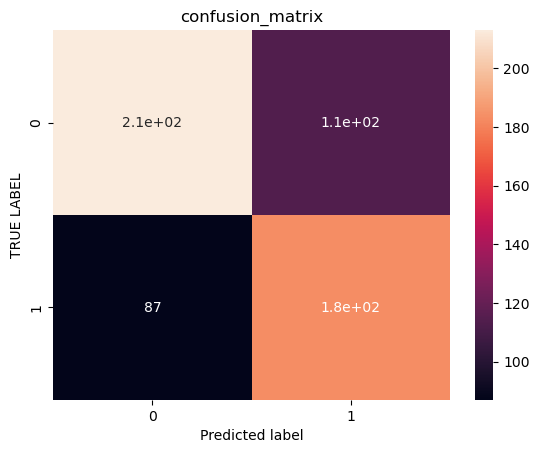

In [ ]:
cm=confusion_matrix(y_pred,y_test)
sns.heatmap(cm,annot=True)
plt.title("confusion_matrix")
plt.xlabel('Predicted label')
plt.ylabel('TRUE LABEL')

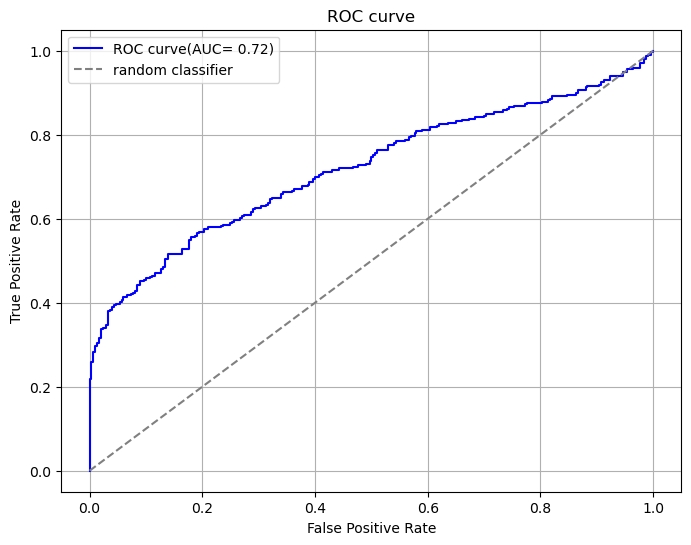

In [ ]:
y_probs=lr_model.predict_proba(x_test)[:,1]
fpr, tpr , thresholds= roc_curve(y_test,y_probs)
auc_score = roc_auc_score(y_test,y_probs)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC curve(AUC= {auc_score:.2f})', color='blue')
plt.plot([0,1],[0,1], linestyle='--',color='gray',label='random classifier')
plt.title('ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.svm import SVC
svm = SVC()
svm.fit(x_train,y_train)

SVC()

In [ ]:
svm_pred=svm.predict(x_test)

In [ ]:
print (f'Accuracy: {accuracy_score(svm_pred,y_test)*100:2f}%')

Accuracy: 64.489112%


In [ ]:
print(classification_report(svm_pred,y_test))

              precision    recall  f1-score   support

           0       0.76      0.62      0.68       370
           1       0.53      0.69      0.60       227

    accuracy                           0.64       597
   macro avg       0.64      0.65      0.64       597
weighted avg       0.67      0.64      0.65       597



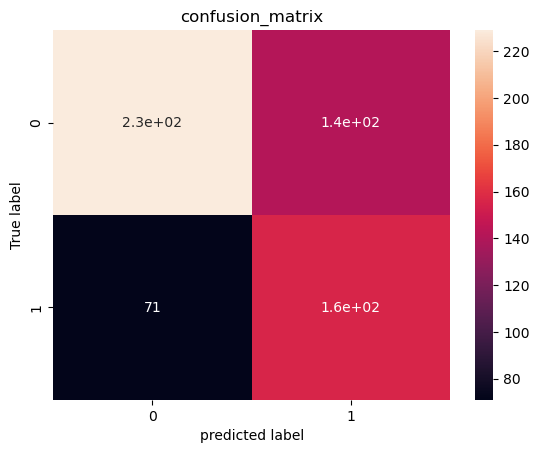

In [ ]:
cm=confusion_matrix(svm_pred,y_test)
sns.heatmap(cm, annot=True)
plt.title('confusion_matrix')
plt.xlabel("predicted label")
plt.ylabel('True label')
plt.show()

In [ ]:
from sklearn.metrics import precision_score , recall_score , f1_score

print(f'Precision: {precision_score(y_test, y_pred)*100:.2f}%')
print(f'Recall: {recall_score(y_test, y_pred)*100:.2f}%')
print(f'F1 Score: {f1_score(y_test, y_pred)*100:.2f}%')

Precision: 67.78%
Recall: 61.62%
F1 Score: 64.55%


In [ ]:
x=df.drop('Reinfection', axis=1)
y=df['Reinfection']

x = pd.get_dummies(x, drop_first=True)
x = x.fillna(0)

x_test,x_train,y_test,y_train=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

lr_model=LogisticRegression(class_weight='balanced')
lr_model.fit(x_train,y_train)

y_pred=lr_model.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(f'Accuracy: {accuracy_score(y_test,y_pred)*100:.2f}%')
print(f'Precision: {precision_score(y_test, y_pred)*100:.2f}%')
print(f'Recall: {recall_score(y_test, y_pred)*100:.2f}%')
print(f'F1 Score: {f1_score(y_test, y_pred)*100:.2f}%')

Accuracy: 60.44%
Precision: 9.88%
Recall: 40.45%
F1 Score: 15.88%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.91      0.62      0.74      2164
           1       0.10      0.40      0.16       220

    accuracy                           0.60      2384
   macro avg       0.51      0.51      0.45      2384
weighted avg       0.84      0.60      0.69      2384



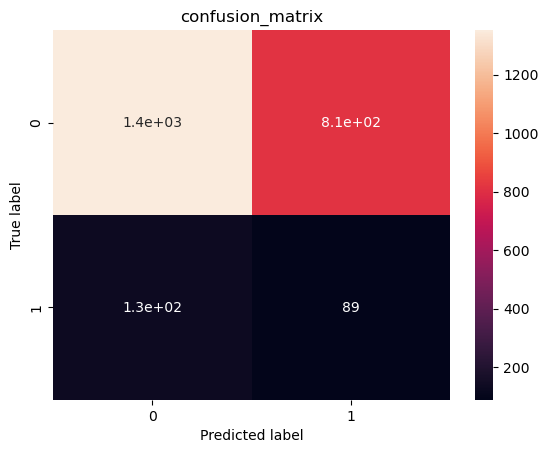

In [ ]:
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm, annot=True)
plt.title('confusion_matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

In [ ]:
from sklearn.svm import SVC

svm = SVC(class_weight='balanced')
svm.fit(x_train,y_train)
svm_pred=svm.predict(x_test)


In [ ]:
print(classification_report(svm_pred,y_test))

              precision    recall  f1-score   support

           0       0.79      0.91      0.84      1883
           1       0.20      0.09      0.12       501

    accuracy                           0.73      2384
   macro avg       0.49      0.50      0.48      2384
weighted avg       0.66      0.73      0.69      2384



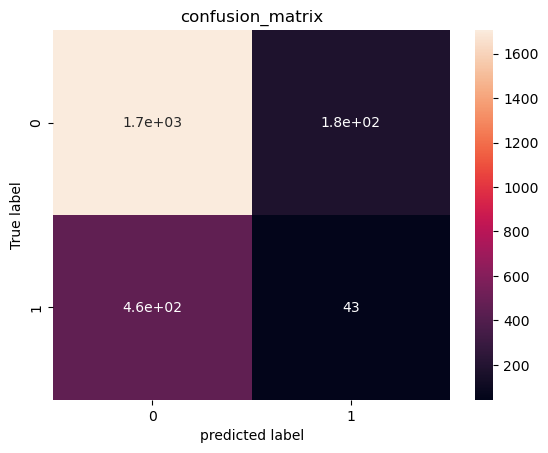

In [ ]:
cm_svm = confusion_matrix(svm_pred,y_test)
sns.heatmap(cm_svm,annot=True)
plt.title('confusion_matrix')
plt.xlabel('predicted label')
plt.ylabel('True label')
plt.show()